# M1 · Compare runs: baseline M1 vs M1 + random rescale
Standalone version of Section 23. Needs only Google Drive (a CPU runtime is fine; no GPU, nothing is retrained).
It reads the saved `metrics.json`, prediction CSVs and split CSVs of `m1_run_001` and `m1_random_rescale`, prints the comparison and saves it to `experiments/m1_random_rescale/comparison/`.

Mounted at /content/drive
Same split for both runs: genimage_unseen-stable_diffusion_v_1_4_n200_seed42

1. Metrics (threshold 0.5) and confusion matrix [TN FP / FN TP]:
              model       split  best_epoch  auroc  accuracy  precision  recall     f1  TN  FP  FN  TP
        baseline M1         val          10 0.8903    0.8417     0.8868  0.7833 0.8319  54   6  13  47
        baseline M1   test_seen          10 0.8126    0.7417     0.7377  0.7500 0.7438  44  16  15  45
        baseline M1 test_unseen          10 0.4014    0.4750     0.4138  0.1200 0.1860 166  34 176  24
M1 + random rescale         val           5 0.8776    0.8500     0.9773  0.7167 0.8269  59   1  17  43
M1 + random rescale   test_seen           5 0.8097    0.7750     0.8667  0.6500 0.7429  54   6  21  39
M1 + random rescale test_unseen           5 0.4183    0.4925     0.4286  0.0450 0.0814 188  12 191   9

2. Change (M1 + random rescale - baseline M1); positive = better:
              auroc  accuracy  precision  r

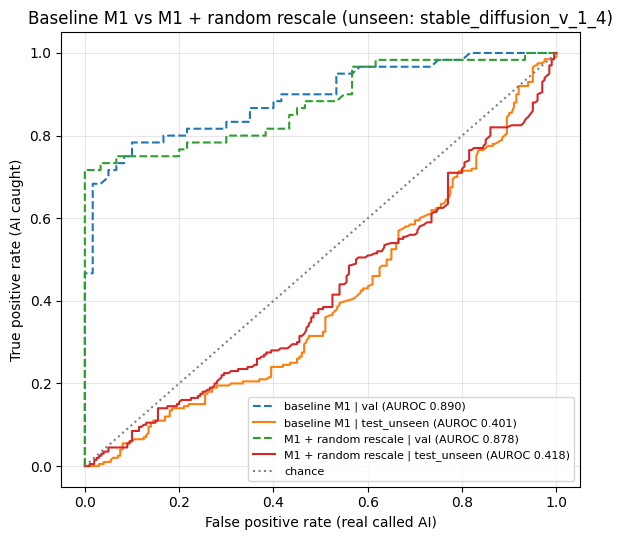


Saved in /content/drive/MyDrive/VeriStamp/experiments/m1_random_rescale/comparison : ['change_new_minus_baseline.csv', 'comparison_baseline_vs_new.csv', 'roc_baseline_vs_new.png', 'shortcut_diagnostic_both.csv']


In [1]:
# 23 · Comparison: baseline M1 vs M1 + random rescale  (STANDALONE: needs only Google Drive, no GPU)
# Reads the saved metrics.json, prediction CSVs and split CSVs of both runs. Nothing is retrained or re-evaluated.
import json
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score
try:
    from google.colab import drive; drive.mount("/content/drive")
except ImportError:
    pass

PROJECT_DIR = "/content/drive/MyDrive/VeriStamp"      # same as Section 1
BASELINE_RUN, NEW_RUN, MODE = "m1_run_001", "m1_random_rescale", "hp_fft"
RESIZE_SHORT_SIDE = 256                              # preprocessing: an image was UPSCALED if its shorter side < 256

EXP = Path(PROJECT_DIR) / "experiments"
RUNS = {"baseline M1": EXP / BASELINE_RUN / MODE, "M1 + random rescale": EXP / NEW_RUN / MODE}
M = {name: json.loads((d / "metrics.json").read_text()) for name, d in RUNS.items()}
split_names = {m["split_name"] for m in M.values()}
assert len(split_names) == 1, f"The two runs used different splits: {split_names}. Not comparable."
SPLIT_DIR = Path(PROJECT_DIR) / "data" / "splits" / split_names.pop()
print("Same split for both runs:", SPLIT_DIR.name)
CMP_DIR = EXP / NEW_RUN / "comparison"; CMP_DIR.mkdir(exist_ok=True)

# 1. metrics + confusion matrix per run and split
rows = []
for name, m in M.items():
    for split in ("val", "test_seen", "test_unseen"):
        (tn, fp), (fn, tp) = m[split]["confusion_matrix"]
        rows.append({"model": name, "split": split, "best_epoch": m["best_epoch"],
                     **{k: round(m[split][k], 4) for k in ("auroc", "accuracy", "precision", "recall", "f1")},
                     "TN": tn, "FP": fp, "FN": fn, "TP": tp})
COMPARISON = pd.DataFrame(rows)
print("\n1. Metrics (threshold 0.5) and confusion matrix [TN FP / FN TP]:")
print(COMPARISON.to_string(index=False))

# 2. change = new run - baseline
base, new = list(M)
keys = ["auroc", "accuracy", "precision", "recall", "f1"]
DELTA = (COMPARISON[COMPARISON.model == new].set_index("split")[keys]
         - COMPARISON[COMPARISON.model == base].set_index("split")[keys]).round(4)
print(f"\n2. Change ({new} - {base}); positive = better:")
print(DELTA.to_string())

# 3. shortcut diagnostic (val + test_seen only): upscaled = shorter side of the ORIGINAL file < 256
sizes = pd.concat([pd.read_csv(SPLIT_DIR / f"{s}.csv", dtype={"image_id": str})[["image_id", "width", "height"]]
                   for s in ("val", "test_seen")])
sizes["upscaled"] = sizes[["width", "height"]].min(axis=1) < RESIZE_SHORT_SIDE
diag = []
for name, d in RUNS.items():
    p = pd.concat([pd.read_csv(d / f"predictions_{s}.csv", dtype={"image_id": str}) for s in ("val", "test_seen")])
    p = p.merge(sizes[["image_id", "upscaled"]], on="image_id", how="left", validate="one_to_one")
    assert p["upscaled"].notna().all(), "some predictions have no size information"
    p["upscaled"] = p["upscaled"].astype(bool)
    r = p[p["label"] == 0]
    row = {"model": name, "real_upscaled_P(AI)": r[r.upscaled].p_ai.mean(), "n_upscaled": int(r.upscaled.sum()),
           "real_not_upscaled_P(AI)": r[~r.upscaled].p_ai.mean()}
    row.update({f"AI_{g}_P(AI)": dd.p_ai.mean() for g, dd in p[p["label"] == 1].groupby("generator")})
    diag.append(row)
DIAG = pd.DataFrame(diag).round(3)
print("\n3. Shortcut diagnostic (mean P(AI), val + test_seen):")
print(DIAG.to_string(index=False))

# 4. ROC: both models on val and on the unseen generator
fig, ax = plt.subplots(figsize=(6, 5.5))
for name, d in RUNS.items():
    for s, ls in (("val", "--"), ("test_unseen", "-")):
        p = pd.read_csv(d / f"predictions_{s}.csv")
        fpr, tpr, _ = roc_curve(p["label"], p["p_ai"])
        ax.plot(fpr, tpr, ls, label=f"{name} | {s} (AUROC {roc_auc_score(p['label'], p['p_ai']):.3f})")
ax.plot([0, 1], [0, 1], ":", color="gray", label="chance")
ax.set_xlabel("False positive rate (real called AI)"); ax.set_ylabel("True positive rate (AI caught)")
ax.set_title(f"Baseline M1 vs M1 + random rescale (unseen: {M[base]['unseen_generator']})")
ax.legend(fontsize=8, loc="lower right"); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig(CMP_DIR / "roc_baseline_vs_new.png", dpi=120); plt.show()

COMPARISON.to_csv(CMP_DIR / "comparison_baseline_vs_new.csv", index=False)
DELTA.to_csv(CMP_DIR / "change_new_minus_baseline.csv")
DIAG.to_csv(CMP_DIR / "shortcut_diagnostic_both.csv", index=False)
print("\nSaved in", CMP_DIR, ":", sorted(p.name for p in CMP_DIR.iterdir()))
